In [ ]:
import os
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PowerTransformer
from sklearn.preprocessing import LabelEncoder 
from sklearn.pipeline import make_pipeline
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.compose import make_column_transformer
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
import shap


In [2]:
os.chdir("/home/kaderi/Feroj/4th paper/data_collection/papilary")

In [ ]:
data = pd.read_csv("Papilary_thyroid_pycombat_integration.csv",index_col= 0)
data

,Control,Control.1,Control.2,Control.3,Control.4,Control.5,Control.6,Control.7,Control.8,Control.9,...,Disease.163,Disease.164,Disease.165,Disease.166,Disease.167,Disease.168,Disease.169,Disease.170,Disease.171,Disease.172
genes,,,,,,,,,,,,,,,,,,,,,
BEST4,3.673299,4.057536,3.884867,3.735956,3.751882,3.621540,3.800490,4.225330,4.143789,3.798373,...,4.133196,4.170679,4.175814,3.750199,4.200860,3.909218,4.369240,3.935019,4.530568,3.922578
CORO6,7.532977,7.387902,8.076503,6.219214,7.094798,7.668475,6.657913,7.194153,8.028238,7.864286,...,7.373057,6.677838,6.607551,6.630912,6.431141,6.685778,6.659187,6.809983,6.578055,6.713796
RAX2,4.780015,4.803900,4.659510,5.141240,4.754181,4.853101,4.832469,4.681616,4.978138,5.066735,...,4.941704,4.845313,4.995205,4.964424,4.805757,5.035122,4.662571,4.923313,4.848558,4.946506
LEAP2,5.648058,5.493352,5.495666,5.487070,5.750994,5.861867,5.584995,5.743157,5.537021,5.489204,...,5.393306,5.403574,5.372267,5.351380,5.328185,5.317029,5.314685,5.420412,5.342229,5.415295
GAPT,4.200096,4.862387,3.463432,3.942281,3.582156,3.508459,3.434738,2.928793,3.279450,3.848538,...,3.644085,3.781006,3.899590,3.841759,3.872908,3.857201,3.842145,3.835194,3.959782,3.842049
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MAN1B1,7.799321,7.529227,7.806208,7.792279,7.695949,7.314930,7.596346,7.775520,7.693368,7.613458,...,7.817071,7.832118,7.762066,7.782847,7.913912,7.782847,7.869874,7.750684,7.865198,7.757626
ZNF783,6.012296,6.106415,5.999944,6.061627,5.957033,6.066082,5.938111,6.027846,6.074146,6.011406,...,5.962156,5.948868,6.074836,6.055435,5.609419,6.250058,5.873783,5.945859,6.023016,5.967046
CX3CL1,7.422724,7.185745,7.949939,7.565847,7.842511,6.777770,7.409934,7.442121,6.924831,7.105286,...,7.019597,7.485768,7.196530,7.061357,7.283788,7.264174,7.342312,7.201441,7.311572,7.193435


In [268]:
control = data[data.columns[data.columns.str.startswith("Con")]]
median_control = control.apply(np.median,axis = 1)
disease = data[data.columns[data.columns.str.startswith("Dis")]]
median_disease = disease.apply(np.median,axis = 1)
median_diff = median_disease - median_control
pd.DataFrame(median_diff)

,0
genes,
BEST4,0.054612
CORO6,-0.118907
RAX2,0.015167
LEAP2,-0.194792
GAPT,0.062563
...,...
MAN1B1,0.085534
ZNF783,-0.007263
CX3CL1,0.559514


In [4]:
data.info()
row_names = data.index
print(row_names)
col_names = data.columns
print(col_names)

<class 'pandas.core.frame.DataFrame'>
Index: 11250 entries, BEST4 to ADAP1
Columns: 304 entries, Control to Disease.172
dtypes: float64(304)
memory usage: 26.2+ MB
Index(['BEST4', 'CORO6', 'RAX2', 'LEAP2', 'GAPT', 'ZNF485', 'MFSD6L', 'SLAMF6',
       'GPBAR1', 'BRSK1',
       ...
       'LPPR2', 'TMEM231', 'GPR153', 'AP1M2', 'GPR124', 'MAN1B1', 'ZNF783',
       'CX3CL1', 'NPEPL1', 'ADAP1'],
      dtype='object', name='genes', length=11250)
Index(['Control', 'Control.1', 'Control.2', 'Control.3', 'Control.4',
       'Control.5', 'Control.6', 'Control.7', 'Control.8', 'Control.9',
       ...
       'Disease.163', 'Disease.164', 'Disease.165', 'Disease.166',
       'Disease.167', 'Disease.168', 'Disease.169', 'Disease.170',
       'Disease.171', 'Disease.172'],
      dtype='object', length=304)


In [5]:
samples = []
for i in col_names:
    if "Dis" in i:
        samples.append('Disease')
    else:
        samples.append("Control")
samples

['Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Co

In [9]:
X= data.select_dtypes(include='float').transpose()

In [10]:
encoder= LabelEncoder()

scaler = StandardScaler()
Y = encoder.fit_transform(samples)
X_train,X_test,y_train,y_test = train_test_split(X,Y,
                                                 random_state= 1000, shuffle= True,train_size= 0.7)

In [11]:
X_train,X_test,y_train,y_test = train_test_split(X,Y,
                                                 random_state= 1000, shuffle= True,train_size= 0.7)

In [274]:


genes = []
roc_score = []
med_diff = []
for i in row_names:
    column_transformer = make_column_transformer(
        (StandardScaler(), [i]),
        remainder='passthrough'
    )
    pipe = Pipeline(steps=[
        ("preprocessing",column_transformer),
        ('model', XGBClassifier(eval_metric='logloss'))
    ])

    param_grid = {
        'model__n_estimators': [50, 100, 150],
        'model__max_depth': [3, 5, 7],
        'model__learning_rate': [0.01, 0.1, 0.2],
        'model__subsample': [0.8, 1],
        'model__colsample_bytree': [0.8, 1]
    }

    grid_search = GridSearchCV(pipe, param_grid, cv=5, scoring='roc_auc', verbose=1, n_jobs=-1)
    grid_search.fit(X_train[[i]],y_train)



    pipe_1 = Pipeline(steps=[
        ("preprocessing",column_transformer),
        ('xgb', XGBClassifier(
                            eval_metric='logloss',
                            n_estimators = grid_search.best_params_.get('model__n_estimators'),
                            learning_rate = grid_search.best_params_.get('model__learning_rate'),
                            max_depth = grid_search.best_params_.get('model__max_depth'),
                            subsample = grid_search.best_params_.get('model__subsample'),
                            colsample_bytree = grid_search.best_params_.get('model__colsample_bytree')
                                                                        
                            ))
    ])


    fitted_model = pipe_1.fit(X_train[[i]],y_train)
    y_prob = fitted_model.predict_proba(X_test[[i]])[:,1]
    score = roc_auc_score(y_score=y_prob,y_true=y_test)

    genes.append(i)
    roc_score.append(score)
    med_diff.append(median_diff.loc[i] )


result = pd.DataFrame({
    'genes': genes,
    'auc_roc_score':roc_score,
    'median_difference':med_diff
})

Fitting 5 folds for each of 108 candidates, totalling 540 fits


Fitting 5 folds for each of 108 candidates, totalling 540 fits
Fitting 5 folds for each of 108 candidates, totalling 540 fits
Fitting 5 folds for each of 108 candidates, totalling 540 fits
Fitting 5 folds for each of 108 candidates, totalling 540 fits
Fitting 5 folds for each of 108 candidates, totalling 540 fits
Fitting 5 folds for each of 108 candidates, totalling 540 fits
Fitting 5 folds for each of 108 candidates, totalling 540 fits
Fitting 5 folds for each of 108 candidates, totalling 540 fits
Fitting 5 folds for each of 108 candidates, totalling 540 fits
Fitting 5 folds for each of 108 candidates, totalling 540 fits
Fitting 5 folds for each of 108 candidates, totalling 540 fits
Fitting 5 folds for each of 108 candidates, totalling 540 fits
Fitting 5 folds for each of 108 candidates, totalling 540 fits
Fitting 5 folds for each of 108 candidates, totalling 540 fits
Fitting 5 folds for each of 108 candidates, totalling 540 fits
Fitting 5 folds for each of 108 candidates, totalling 5

In [275]:
result

,genes,auc_roc_score,median_difference
0,BEST4,0.390905,0.054612
1,CORO6,0.561200,-0.118907
2,RAX2,0.553459,0.015167
3,LEAP2,0.779874,-0.194792
4,GAPT,0.531447,0.062563
...,...,...,...
11245,MAN1B1,0.667634,0.085534
11246,ZNF783,0.430818,-0.007263
11247,CX3CL1,0.911708,0.559514
11248,NPEPL1,0.682390,-0.076660


In [ ]:
up_DEG = result[(result['auc_roc_score']>=0.9) & (result['median_difference']>1)]
up_DEG

,genes,auc_roc_score,median_difference
651,CDH3,0.998065,1.442336
851,SLC34A2,0.929124,1.720964
1064,QPCT,0.958394,1.150379
1239,RXRG,0.989840,1.595341
1377,KCNJ2,0.941703,1.756205
1425,CITED1,0.949686,1.939338
1487,PROS1,0.976294,1.040231
1630,LAMB3,0.924770,1.581983
1644,ECM1,0.932027,1.488870
1909,LRP4,0.970972,1.991650


In [295]:
up_DEG.to_csv(path_or_buf='PTC_up_deg_machine_learning_xg_boost(1&0.9).csv')

In [328]:
down_DEG = result[result['median_difference']<0]
down_DEG

,genes,auc_roc_score,median_difference
1,CORO6,0.561200,-0.118907
3,LEAP2,0.779874,-0.194792
5,ZNF485,0.423319,-0.031166
6,MFSD6L,0.567247,-0.035757
10,IQCD,0.520077,-0.008727
...,...,...,...
11239,MOSPD2,0.638365,-0.145222
11241,TMEM231,0.669811,-0.130175
11244,GPR124,0.575955,-0.034746
11246,ZNF783,0.430818,-0.007263


In [297]:
down_DEG.to_csv(path_or_buf='PTC_down_deg_machine_learning_xg_boost(-1&0.9).csv')

In [245]:
pd.DataFrame(columns=['genes','score','median_diff'])

,genes,score,median_diff


In [ ]:
ptc_limma_up = pd.read_csv(filepath_or_buffer="PTC_up_regulated_data_(0.01 & greater than 2).csv")
ptc_limma_up

,Unnamed: 0,logFC,AveExpr,t,P.Value,adj.P.Val,B
0,GALE,0.890459,6.006070,22.974007,1.674482e-68,1.883793e-64,145.427774
1,DPP4,1.918134,7.310482,22.763497,9.899758e-68,5.568614e-64,143.661783
2,SHROOM4,1.239521,6.008908,22.316756,4.360899e-66,1.635337e-62,139.899605
3,TUSC3,1.302315,6.291113,22.222857,9.686111e-66,2.724219e-62,139.106422
4,TNFRSF10B,0.724872,6.814803,22.120566,2.312593e-65,4.336111e-62,138.241411
...,...,...,...,...,...,...,...
219,STAT4,0.728151,5.845819,8.282358,3.847504e-15,1.916936e-14,23.409317
220,CD1A,0.760279,4.658941,8.248579,4.848974e-15,2.392586e-14,23.181239
221,F5,0.766473,4.984079,8.106158,1.277916e-14,6.058386e-14,22.226136
222,LAMP3,0.903783,6.895577,7.323046,2.171685e-12,8.527560e-12,17.172987


In [ ]:
ptc_xgboost_up  = pd.read_csv(filepath_or_buffer= "PTC_up_deg_machine_learning_xg_boost(1&0.9).csv",
                              usecols=["genes","auc_roc_score","median_difference"])
ptc_xgboost_up

,genes,auc_roc_score,median_difference
0,TIMP1,0.945573,0.892585
1,SDC4,0.991534,0.817891
2,CDKN1A,0.916304,0.829875
3,EPS8,0.999516,0.750019
4,CDH3,0.998065,1.442336
...,...,...,...
103,FAM20A,0.957184,1.290367
104,SYTL5,0.963232,1.153153
105,NGEF,0.941703,0.821963
106,SHROOM4,0.990324,1.166364


In [ ]:
pd.merge(left=ptc_xgboost_up,right=ptc_limma_up,
         how='inner', left_on='genes', right_on="Unnamed: 0")

,genes,auc_roc_score,median_difference,Unnamed: 0,logFC,AveExpr,t,P.Value,adj.P.Val,B
0,TIMP1,0.945573,0.892585,TIMP1,1.203264,11.509641,15.409280,5.022447e-40,1.852542e-38,80.232246
1,SDC4,0.991534,0.817891,SDC4,1.102237,10.827343,17.688161,1.111861e-48,1.078314e-46,100.048270
2,CDKN1A,0.916304,0.829875,CDKN1A,1.022368,9.042371,13.458752,9.877793e-33,1.995066e-31,63.541284
3,EPS8,0.999516,0.750019,EPS8,0.969739,10.112541,19.603653,6.007753e-56,1.469287e-53,116.688975
4,CDH3,0.998065,1.442336,CDH3,1.635239,7.318217,21.170755,7.806948e-62,7.514584e-59,130.165128
...,...,...,...,...,...,...,...,...,...,...
101,FAM20A,0.957184,1.290367,FAM20A,1.495075,6.136447,16.381390,1.038664e-43,5.511780e-42,88.667330
102,SYTL5,0.963232,1.153153,SYTL5,1.384921,4.897066,18.147417,1.992639e-50,2.410450e-48,104.047753
103,NGEF,0.941703,0.821963,NGEF,0.977700,5.095091,16.779490,3.185838e-45,2.002273e-43,92.132127
104,SHROOM4,0.990324,1.166364,SHROOM4,1.239521,6.008908,22.316756,4.360899e-66,1.635337e-62,139.899605


In [340]:
ptc_limma_down = pd.read_csv(filepath_or_buffer="PTC_Down_regulated_data_(0.001 & ess than -.7).csv")
ptc_limma_down

,Unnamed: 0,logFC,AveExpr,t,P.Value,adj.P.Val,B
0,MMRN1,-1.960303,5.585063,-21.592537,2.096673e-63,2.948447e-60,133.761142
1,PLA2R1,-1.077234,5.973232,-21.039885,2.405317e-61,1.932844e-58,129.046423
2,ATP2C2,-0.824731,4.841122,-20.816919,1.640898e-60,9.715845e-58,127.137391
3,LYVE1,-1.847648,5.845223,-20.445470,4.053468e-59,1.982675e-56,123.948889
4,TFF3,-2.062941,9.532046,-20.350744,9.197517e-59,4.138882e-56,123.134204
...,...,...,...,...,...,...,...
175,MFAP5,-0.827100,5.666995,-9.722207,1.225355e-19,8.615778e-19,33.637966
176,CA4,-0.798011,6.752695,-9.624812,2.538896e-19,1.746947e-18,32.917253
177,H19,-0.766715,6.221445,-9.190954,6.218147e-18,3.849981e-17,29.754796
178,HSD17B6,-0.764108,8.693755,-8.185159,7.474976e-15,3.613815e-14,22.754619


In [341]:
ptc_xgboost_down  = pd.read_csv(filepath_or_buffer= "PTC_down_deg_machine_learning_xg_boost(-0.7&0.9).csv",
                              usecols=["genes","auc_roc_score","median_difference"])
ptc_xgboost_down

,genes,auc_roc_score,median_difference
0,KBTBD11,0.946783,-0.736815
1,ELMO1,0.977020,-1.020547
2,CCL21,0.961297,-1.418876
3,TFF3,0.969763,-1.750541
4,KIT,0.952104,-1.151286
...,...,...,...
92,DGKI,0.943154,-1.277925
93,TMEM171,0.949927,-0.891901
94,RASSF9,0.954282,-0.795628
95,ART4,0.973391,-0.786397


In [342]:
pd.merge(left=ptc_xgboost_down,right=ptc_limma_down,
         how='inner', left_on='genes', right_on="Unnamed: 0")

,genes,auc_roc_score,median_difference,Unnamed: 0,logFC,AveExpr,t,P.Value,adj.P.Val,B
0,KBTBD11,0.946783,-0.736815,KBTBD11,-0.833451,5.692544,-15.894567,7.312104e-42,3.251430e-40,84.437348
1,ELMO1,0.977020,-1.020547,ELMO1,-1.288325,7.407665,-16.290609,2.297696e-43,1.169641e-41,87.877850
2,CCL21,0.961297,-1.418876,CCL21,-1.785834,7.962718,-18.124220,2.441259e-50,2.890964e-48,103.845823
3,TFF3,0.969763,-1.750541,TFF3,-2.062941,9.532046,-20.350744,9.197517e-59,4.138882e-56,123.134204
4,KIT,0.952104,-1.151286,KIT,-1.440037,8.345574,-16.466002,4.954435e-44,2.757112e-42,89.403391
...,...,...,...,...,...,...,...,...,...,...
92,DGKI,0.943154,-1.277925,DGKI,-1.443377,6.619797,-16.572758,1.946500e-44,1.122981e-42,90.332381
93,TMEM171,0.949927,-0.891901,TMEM171,-0.917505,6.398583,-18.626242,3.023226e-52,4.475169e-50,108.212864
94,RASSF9,0.954282,-0.795628,RASSF9,-0.998985,5.137211,-17.400971,1.376522e-47,1.200455e-45,97.546112
95,ART4,0.973391,-0.786397,ART4,-0.885618,4.180976,-19.417068,3.047262e-55,6.348463e-53,115.074295


In [333]:
np.intersect1d(ptc_xgboost_down['genes'],ptc_limma_down['x'])

array(['ADH1B', 'AGPAT4', 'AGR3', 'AKR1C2', 'AOX1', 'ARHGAP24', 'ART4',
       'ATP2C2', 'BEX1', 'CCDC146', 'CCL21', 'CDH16', 'CFD', 'CLCNKA',
       'CLCNKB', 'CLUL1', 'COL23A1', 'CRABP1', 'CSGALNACT1', 'CUX2',
       'DDX25', 'DGKI', 'DIO1', 'DIRAS2', 'DLG2', 'DPP6', 'DPT',
       'DYNLRB2', 'ELMO1', 'EPHB1', 'FAM167A', 'FBLN1', 'FBXO15', 'FIBIN',
       'GDF10', 'GHR', 'GJB6', 'GLT8D2', 'GPM6A', 'GPR83', 'HGD',
       'IGFBPL1', 'IP6K3', 'KBTBD11', 'KCNIP4', 'KIAA1324', 'KIT',
       'LINGO2', 'LMOD1', 'LRP1B', 'LYVE1', 'MFAP4', 'MMRN1', 'MPPED2',
       'NUPR1', 'OCA2', 'ODAM', 'OGN', 'OMD', 'OTOS', 'PAPSS2', 'PBX4',
       'PCOLCE2', 'PKHD1L1', 'PKNOX2', 'PLA2R1', 'RASSF9', 'RELN',
       'RNF150', 'ROR2', 'RYR2', 'SCARA5', 'SCN3B', 'SCNN1B', 'SGCD',
       'SLC26A7', 'SLC4A4', 'SLITRK5', 'SMAD9', 'SMOC2', 'SOD3',
       'SOSTDC1', 'STEAP2', 'TBX22', 'TCEAL2', 'TCF7L1', 'TFCP2L1',
       'TFF3', 'TFPI', 'TMEM171', 'TPO', 'UGT8', 'WDR72', 'WSCD2',
       'ZFPM2', 'ZMAT4', 'ZNF536']

In [ ]:
ptc_xgboost_down['genes']

0     KBTBD11
1       ELMO1
2       CCL21
3        TFF3
4         KIT
       ...   
92       DGKI
93    TMEM171
94     RASSF9
95       ART4
96      SMOC2
Name: genes, Length: 97, dtype: object

AUC Score: 0.592


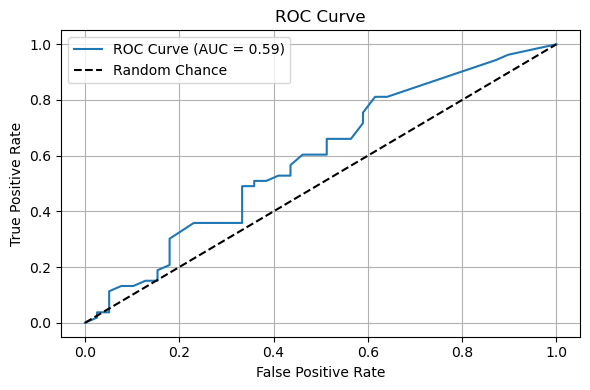

In [ ]:
# auc = roc_auc_score(y_test, y_pred)
# print(f"AUC Score: {auc:.3f}")


# fpr, tpr, thresholds = roc_curve(encoder.fit_transform(y_test), y_pred)

# plt.figure(figsize=(6, 4))
# plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc:.2f})')
# plt.plot([0, 1], [0, 1], 'k--', label='Random Chance')
# plt.xlabel('False Positive Rate')
# plt.ylabel('True Positive Rate')
# plt.title('ROC Curve')
# plt.legend()
# plt.grid(True)
# plt.tight_layout()
# plt.show()

In [ ]:
X =  data.select_dtypes(include='float')
X

genes
1
2
3
4
5
...
300
301
302
303
